# Thermal desalination: MVC and MED (`difflow_water.thermal`)

Two whole-plant blocks:

- **Mechanical vapor compression** (`mvc_performance`, palette `MVCDesalinator`): WaterTAP 1.8.0's single-stage MVC flowsheet, equation for equation. It reproduces WaterTAP's model to 4e-7 on every output (`benchmarks/watertap/compare_mvc.py`).
- **Multi-effect distillation** (`med_performance`, palette `MEDDesalinator`): parallel feed, per-effect mass and energy balances on the Sharqawy seawater properties.

Both are differentiable. Below: the LCOW of an MVC plant minimized over its design with `jax.grad` (WaterTAP's optimum is the check), the two ways of closing the MVC energy balance, and the gain output ratio of MED against the number of effects. The design numbers and costs are WaterTAP's example values (ILLUSTRATIVE).

In [1]:
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

import difflow_water as dw
from difflow_water.thermal import MEDParams, MVCParams, med_performance, mvc_performance

# WaterTAP's example feed: 40 kg/s of water at 100 g/kg, 25 C
feed = dw.make_seawater_stream(flow_mass=40.0 / 0.9, salinity=0.1)
out = mvc_performance(feed, MVCParams())
for k in ["pressure_ratio", "evaporator_area", "T_condensate", "SEC", "LCOW"]:
    print(f"{k:18s} {float(out[k]):10.4f}")

pressure_ratio         1.6024
evaporator_area      792.3240
T_condensate         355.4462
SEC                   22.0561
LCOW                   4.5193


## Closing the energy balance

With no external heat, the compressor's work has to match what the plant absorbs. With the pressure ratio fixed (WaterTAP's simulation degrees of freedom, `mode="fixed_pressure_ratio"`), most designs miss: the condensate would have to leave hotter than saturation (`condensate_subcooling < 0`; WaterTAP reports these as infeasible) or colder than the brine (`evaporator_dT_out < 0`). The default `mode="saturated_condensate"` solves the pressure ratio for saturated condensate instead. The sweep shows the window of feasible fixed ratios at one design.

feasible fixed ratios at this design: 1.540 - 1.600


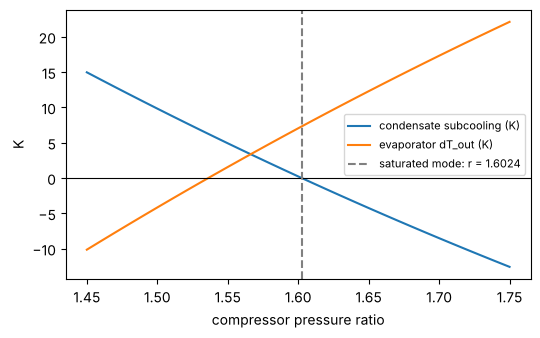

In [2]:
prs = np.linspace(1.45, 1.75, 31)
sub, dTo = [], []
for pr in prs:
    o = mvc_performance(feed, MVCParams(mode="fixed_pressure_ratio", pressure_ratio=pr))
    sub.append(float(o["condensate_subcooling"])); dTo.append(float(o["evaporator_dT_out"]))
sat = float(out["pressure_ratio"])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(prs, sub, label="condensate subcooling (K)")
ax.plot(prs, dTo, label="evaporator dT_out (K)")
ax.axhline(0, color="k", lw=0.8); ax.axvline(sat, ls="--", color="gray", label=f"saturated mode: r = {sat:.4f}")
ax.set_xlabel("compressor pressure ratio"); ax.set_ylabel("K"); ax.legend(fontsize=8)
feasible = prs[(np.array(sub) >= 0) & (np.array(dTo) > 0)]
print(f"feasible fixed ratios at this design: {feasible.min():.3f} - {feasible.max():.3f}")

## Minimum LCOW with `jax.grad`

WaterTAP's example optimizes brine temperature (vapor at most 75 C), pressure ratio and the two preheater areas for minimum LCOW with IPOPT. The same problem here: SLSQP, gradients of the LCOW and of the two feasibility margins from `jax`, through the plant's Newton solve (implicit differentiation). Fixed-ratio mode keeps the four decisions WaterTAP has; the start is a feasible design. The preheater sign convention follows WaterTAP's example (`hx_dP = -7e3`, see the docs) so the optimum is directly comparable.

In [3]:
def run(x):
    return mvc_performance(feed, MVCParams(mode="fixed_pressure_ratio", T_brine=x[0], pressure_ratio=x[1],
                                           A_hx_distillate=x[2], A_hx_brine=x[3], hx_dP=-7e3))

f = jax.jit(lambda x: run(x)["LCOW"])
g = jax.jit(jax.grad(lambda x: run(x)["LCOW"]))
def cons(x):
    o = run(x)
    return jnp.stack([o["condensate_subcooling"], o["evaporator_dT_out"], 450.0 - o["T_compressed_vapor"]])
c, cj = jax.jit(cons), jax.jit(jax.jacfwd(cons))
x0 = np.array([348.15, 1.58, 199.0, 174.0])
res = minimize(lambda x: float(f(x)), x0, jac=lambda x: np.asarray(g(x)), method="SLSQP",
               bounds=[(273.15, 348.15), (1.0, 5.0), (10.0, None), (10.0, None)],
               constraints=[{"type": "ineq", "fun": lambda x: np.asarray(c(x)), "jac": lambda x: np.asarray(cj(x))}],
               options={"ftol": 1e-12, "maxiter": 200})
print(res.message, res.nit, "iterations")
watertap = {"T_brine": 348.15, "pressure_ratio": 1.604816, "A_hx_distillate": 199.2295, "A_hx_brine": 174.4172, "LCOW": 4.518535}
for k, v in zip(["T_brine", "pressure_ratio", "A_hx_distillate", "A_hx_brine"], res.x):
    print(f"{k:16s} difflow {v:10.5f}   WaterTAP {watertap[k]:10.5f}")
print(f"{'LCOW':16s} difflow {res.fun:10.5f}   WaterTAP {watertap['LCOW']:10.5f}  USD/m3")

Optimization terminated successfully 42 iterations
T_brine          difflow  348.15000   WaterTAP  348.15000
pressure_ratio   difflow    1.60482   WaterTAP    1.60482
A_hx_distillate  difflow  199.22949   WaterTAP  199.22950
A_hx_brine       difflow  174.41715   WaterTAP  174.41720
LCOW             difflow    4.51854   WaterTAP    4.51853  USD/m3


At the optimum the brine temperature sits on its bound and the condensate leaves exactly saturated: the optimum lies on the boundary the saturated-condensate mode follows. Where the LCOW goes, by unit:

SEC 22.12 kWh/m3, compressor 1.78 MW, evaporator 789 m2


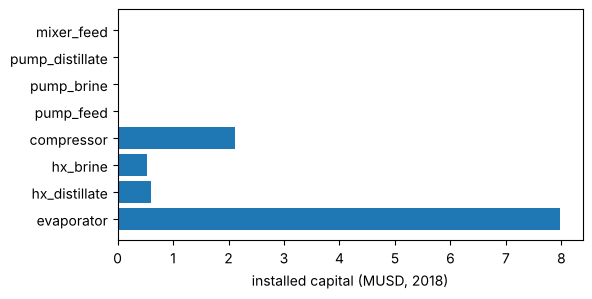

In [4]:
o = run(res.x)
cap = {k: float(v) for k, v in o["capital"].items()}
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(list(cap), [v / 1e6 for v in cap.values()])
ax.set_xlabel("installed capital (MUSD, 2018)")
print(f"SEC {float(o['SEC']):.2f} kWh/m3, compressor {float(o['compressor_work'])/1e6:.2f} MW, evaporator {float(o['evaporator_area']):.0f} m2")

## MED: gain output ratio against the number of effects

A parallel-feed MED plant fed 20 kg/s of 35 g/kg seawater, brine from 65 C (first effect) to 40 C (last), 1 kg/s of motive steam at 70 C. Each effect heats its own share of the feed from 35 C inside the effect, which caps the GOR well below the number of effects (no inter-effect preheaters are modelled). `jax.grad` gives the sensitivity of the GOR to the top brine temperature at each N.

N= 2  GOR  0.87  dGOR/dT_top -0.033 1/K
N= 3  GOR  1.49  dGOR/dT_top -0.044 1/K
N= 4  GOR  2.11  dGOR/dT_top -0.055 1/K
N= 5  GOR  2.73  dGOR/dT_top -0.066 1/K
N= 6  GOR  3.35  dGOR/dT_top -0.077 1/K
N= 7  GOR  3.97  dGOR/dT_top -0.088 1/K
N= 8  GOR  4.59  dGOR/dT_top -0.099 1/K
N= 9  GOR  5.21  dGOR/dT_top -0.110 1/K
N=10  GOR  5.84  dGOR/dT_top -0.121 1/K
N=11  GOR  6.47  dGOR/dT_top -0.132 1/K
N=12  GOR  7.10  dGOR/dT_top -0.143 1/K


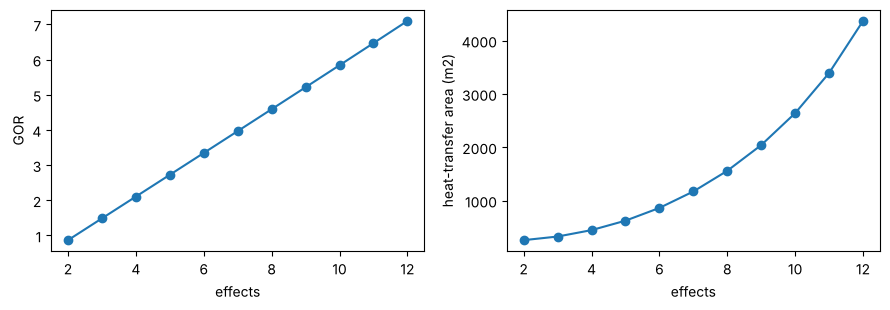

In [5]:
sea = dw.make_seawater_stream(flow_mass=20.0, salinity=0.035)
Ns = range(2, 13)
gor, dgor, area = [], [], []
for N in Ns:
    fn = lambda Tt, N=N: med_performance(sea, MEDParams(n_effects=N, T_top=Tt))["GOR"]
    gor.append(float(fn(338.15))); dgor.append(float(jax.grad(fn)(338.15)))
    area.append(float(med_performance(sea, MEDParams(n_effects=N))["area_total"]))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(list(Ns), gor, "o-"); ax[0].set_xlabel("effects"); ax[0].set_ylabel("GOR")
ax[1].plot(list(Ns), area, "o-"); ax[1].set_xlabel("effects"); ax[1].set_ylabel("heat-transfer area (m2)")
fig.tight_layout()
for N, a, b in zip(Ns, gor, dgor):
    print(f"N={N:2d}  GOR {a:5.2f}  dGOR/dT_top {b:+.3f} 1/K")

## What this shows, and what it does not

- The MVC model is WaterTAP's model: the agreement is an implementation check, not a plant validation.
- The MED model is mass and energy balances only; it has no WaterTAP counterpart and no independent cross-check yet.
- Costs are WaterTAP's example values, a benchmark convention.